# Policy Gradient Methods: REINFORCE, Actor-Critic, and PPO


## 1. Setup

In [1]:
# !pip install -q "gymnasium[box2d]" torch matplotlib numpy

## 2. Implementation


In [2]:
import numpy as np, torch, torch.nn as nn, gymnasium as gym
import matplotlib.pyplot as plt
from torch.distributions import Categorical, Normal

torch.set_num_threads(1)

class OneHot(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.n = env.observation_space.n
        self.observation_space = gym.spaces.Box(0, 1, (self.n,), np.float32)
    def observation(self, o):
        v = np.zeros(self.n, np.float32); v[o] = 1.0
        return v

def make_env(name, max_steps):
    env = gym.make(name, max_episode_steps=max_steps)
    if isinstance(env.observation_space, gym.spaces.Discrete):
        env = OneHot(env)
    return env

### Per-environment configuration

In [3]:
CONFIGS = {
    "CartPole-v1":     dict(episodes=500,  hidden=(64, 64),   lr_pi=1e-3, lr_v=1e-3, gamma=0.99, reward_scale=0.01, max_steps=500),
    "Acrobot-v1":      dict(episodes=500,  hidden=(64, 64),   lr_pi=1e-3, lr_v=5e-3, gamma=0.99, reward_scale=0.1,  max_steps=500),
    "LunarLander-v3":  dict(episodes=1000, hidden=(128, 128), lr_pi=5e-4, lr_v=1e-3, gamma=0.99, reward_scale=0.01, max_steps=1000),
    "Pendulum-v1":     dict(episodes=1500, hidden=(64, 64),   lr_pi=1e-3, lr_v=1e-3, gamma=0.99, reward_scale=0.1,  max_steps=200),
    "CliffWalking-v1": dict(episodes=200,  hidden=(32,),      lr_pi=3e-3, lr_v=3e-3, gamma=0.99, reward_scale=0.05, max_steps=200),
}
N_SEEDS = 5

### Networks

In [4]:
def mlp(inp, hidden, out):
    layers, d = [], inp
    for h in hidden:
        layers += [nn.Linear(d, h), nn.Tanh()]; d = h
    layers.append(nn.Linear(d, out))
    return nn.Sequential(*layers)

class Policy(nn.Module):
    def __init__(self, env, hidden):
        super().__init__()
        obs_dim = env.observation_space.shape[0]
        self.discrete = isinstance(env.action_space, gym.spaces.Discrete)
        if self.discrete:
            self.net = mlp(obs_dim, hidden, env.action_space.n)
        else:
            self.net = mlp(obs_dim, hidden, env.action_space.shape[0])
            self.log_std = nn.Parameter(torch.full((env.action_space.shape[0],), -0.5))
            self.low = torch.as_tensor(env.action_space.low)
            self.high = torch.as_tensor(env.action_space.high)
    def dist(self, s):
        out = self.net(s)
        if self.discrete:
            return Categorical(logits=out)
        return Normal(out, self.log_std.exp())
    def log_prob(self, d, a):
        lp = d.log_prob(a)
        return lp if self.discrete else lp.sum(-1)
    def to_env(self, a):
        if self.discrete:
            return int(a.item())
        return torch.clamp(a, self.low, self.high).numpy()

def make_value(env, hidden):
    return mlp(env.observation_space.shape[0], hidden, 1)

### Algorithms

- **REINFORCE:** episodic Monte Carlo policy gradient.
- **REINFORCE with baseline:** Monte Carlo policy gradient with a learned state-value baseline.
- **Actor-Critic:** one-step temporal-difference policy gradient.
- **PPO:** clipped policy objective, generalized advantage estimation (GAE), and multiple mini-batch updates per rollout. For Pendulum, the original Gaussian policy samples an unbounded latent action that is clipped before reaching the environment; PPO computes likelihood ratios for the sampled latent action.

In [5]:
def rollout(env, pi):
    obs, _ = env.reset()
    S, A, R, done = [], [], [], False
    while not done:
        s = torch.as_tensor(obs, dtype=torch.float32)
        with torch.no_grad():
            a = pi.dist(s).sample()
        obs, r, term, trunc, _ = env.step(pi.to_env(a))
        S.append(s); A.append(a); R.append(r)
        done = term or trunc
    return torch.stack(S), torch.stack(A), R

def returns_to_go(R, gamma, scale):
    G, out = 0.0, []
    for r in reversed(R):
        G = r * scale + gamma * G
        out.append(G)
    return torch.tensor(out[::-1], dtype=torch.float32)

def train_episodic(env, cfg, use_baseline, seed):
    pi = Policy(env, cfg["hidden"])
    opt_pi = torch.optim.Adam(pi.parameters(), lr=cfg["lr_pi"])
    if use_baseline:
        V = make_value(env, cfg["hidden"])
        opt_v = torch.optim.Adam(V.parameters(), lr=cfg["lr_v"])
    scores = []
    for ep in range(cfg["episodes"]):
        S, A, R = rollout(env, pi)
        scores.append(sum(R))
        G = returns_to_go(R, cfg["gamma"], cfg["reward_scale"])
        disc = cfg["gamma"] ** torch.arange(len(R), dtype=torch.float32)
        if use_baseline:
            v = V(S).squeeze(-1)
            delta = (G - v).detach()
            loss_v = ((G - v) ** 2).mean()
            opt_v.zero_grad(); loss_v.backward(); opt_v.step()
        else:
            delta = G
        logp = pi.log_prob(pi.dist(S), A)
        loss_pi = -(disc * delta * logp).mean()
        opt_pi.zero_grad(); loss_pi.backward(); opt_pi.step()
    return scores

def train_actor_critic(env, cfg, seed):
    pi = Policy(env, cfg["hidden"])
    V = make_value(env, cfg["hidden"])
    opt_pi = torch.optim.Adam(pi.parameters(), lr=cfg["lr_pi"])
    opt_v = torch.optim.Adam(V.parameters(), lr=cfg["lr_v"])
    gamma, scale = cfg["gamma"], cfg["reward_scale"]
    scores = []
    for ep in range(cfg["episodes"]):
        obs, _ = env.reset()
        I, total, done = 1.0, 0.0, False
        while not done:
            s = torch.as_tensor(obs, dtype=torch.float32)
            d = pi.dist(s)
            a = d.sample()
            logp = pi.log_prob(d, a)
            obs, r, term, trunc, _ = env.step(pi.to_env(a))
            total += r
            s2 = torch.as_tensor(obs, dtype=torch.float32)
            with torch.no_grad():
                v_next = torch.zeros(1) if term else V(s2)
            target = r * scale + gamma * v_next
            v = V(s)
            delta = (target - v).detach()
            loss_v = ((target - v) ** 2).mean()
            loss_pi = -(I * delta * logp).sum()
            opt_v.zero_grad(); loss_v.backward(); opt_v.step()
            opt_pi.zero_grad(); loss_pi.backward(); opt_pi.step()
            I *= gamma
            done = term or trunc
        scores.append(total)
    return scores

ALGOS = {
    "REINFORCE":               lambda env, cfg, seed: train_episodic(env, cfg, False, seed),
    "REINFORCE with baseline": lambda env, cfg, seed: train_episodic(env, cfg, True, seed),
    "Actor-Critic":            lambda env, cfg, seed: train_actor_critic(env, cfg, seed),
}

def train_ppo(env, cfg, seed, rollout_steps=1024, epochs=5, minibatch=64,
              clip=0.2, gae_lambda=0.95, entropy_coef=0.0):
    pi = Policy(env, cfg['hidden'])
    value = make_value(env, cfg['hidden'])
    optimizer_pi = torch.optim.Adam(pi.parameters(), lr=cfg['lr_pi'])
    optimizer_v = torch.optim.Adam(value.parameters(), lr=cfg['lr_v'])
    gamma, scale = cfg['gamma'], cfg['reward_scale']
    obs, _ = env.reset(seed=seed)
    scores, episode_return = [], 0.0
    while len(scores) < cfg['episodes']:
        states, actions, old_logps, rewards, values, next_values, boundaries = [], [], [], [], [], [], []
        while len(states) < rollout_steps and len(scores) < cfg['episodes']:
            state = torch.as_tensor(obs, dtype=torch.float32)
            with torch.no_grad():
                dist = pi.dist(state)
                action = dist.sample()
                logp = pi.log_prob(dist, action)
                val = value(state).squeeze(-1)
            next_obs, reward, terminated, truncated, _ = env.step(pi.to_env(action))
            with torch.no_grad():
                next_val = 0.0 if terminated else value(torch.as_tensor(next_obs, dtype=torch.float32)).item()
            states.append(state); actions.append(action); old_logps.append(logp)
            rewards.append(reward * scale); values.append(val.item()); next_values.append(next_val)
            boundaries.append(terminated or truncated)
            episode_return += reward
            obs = next_obs
            if terminated or truncated:
                scores.append(episode_return)
                episode_return = 0.0
                if len(scores) < cfg['episodes']:
                    obs, _ = env.reset()

        advantages = np.zeros(len(rewards), dtype=np.float32)
        gae = 0.0
        for i in reversed(range(len(rewards))):
            delta = rewards[i] + gamma * next_values[i] - values[i]
            gae = delta + gamma * gae_lambda * (1.0 - float(boundaries[i])) * gae
            advantages[i] = gae
        S, A, old_lp = torch.stack(states), torch.stack(actions), torch.stack(old_logps)
        adv = torch.from_numpy(advantages)
        targets = adv + torch.tensor(values, dtype=torch.float32)
        adv = (adv - adv.mean()) / (adv.std(unbiased=False) + 1e-8)
        for _ in range(epochs):
            for idx in torch.randperm(len(S)).split(minibatch):
                d = pi.dist(S[idx])
                ratio = (pi.log_prob(d, A[idx]) - old_lp[idx]).exp()
                objective = torch.minimum(ratio * adv[idx], ratio.clamp(1-clip, 1+clip) * adv[idx])
                entropy = d.entropy()
                if not pi.discrete:
                    entropy = entropy.sum(-1)
                loss_pi = -objective.mean() - entropy_coef * entropy.mean()
                loss_v = ((value(S[idx]).squeeze(-1) - targets[idx]) ** 2).mean()
                optimizer_pi.zero_grad(); loss_pi.backward()
                torch.nn.utils.clip_grad_norm_(pi.parameters(), 0.5); optimizer_pi.step()
                optimizer_v.zero_grad(); loss_v.backward()
                torch.nn.utils.clip_grad_norm_(value.parameters(), 0.5); optimizer_v.step()
    return scores

ALGOS['PPO'] = train_ppo


### Running experiments and plotting


In [6]:
def run_one(env_name, algo_name, seed):
    cfg = CONFIGS[env_name]
    torch.manual_seed(seed); np.random.seed(seed)
    env = make_env(env_name, cfg["max_steps"])
    try:
        env.reset(seed=seed); env.action_space.seed(seed)
        return ALGOS[algo_name](env, cfg, seed)
    finally:
        env.close()

def smooth(x, k=10):
    return np.convolve(x, np.ones(k) / k, mode="valid")

def plot_env(env_name, results):
    colors = {"REINFORCE": "tab:red", "REINFORCE with baseline": "tab:green", "Actor-Critic": "tab:blue", "PPO": "tab:purple"}
    plt.figure(figsize=(8, 5))
    for algo, arr in results.items():
        smoothed = np.stack([smooth(run) for run in arr])
        mean, sd = smoothed.mean(axis=0), smoothed.std(axis=0)
        x = np.arange(10, 10 + len(mean))
        plt.plot(x, mean, label=algo, color=colors[algo])
        plt.fill_between(x, mean-sd, mean+sd, color=colors[algo], alpha=0.15)
    plt.xlabel("Training episode"); plt.ylabel("Undiscounted episode return")
    plt.title(f"{env_name} (mean ± SD across seeds)")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(f"results_ppo/{env_name}.png", dpi=150); plt.show()

In [7]:
from pathlib import Path
import csv

RESULTS_DIR = Path("results_ppo")
RESULTS_DIR.mkdir(exist_ok=True)

def run_env_cached(name, n_seeds=N_SEEDS):
    results = {}
    for algo in ALGOS:
        runs = []
        safe_algo = algo.replace(" ", "_")
        for seed in range(n_seeds):
            path = RESULTS_DIR / f"{name}_{safe_algo}_seed{seed}.npy"
            if path.exists():
                scores = np.load(path, allow_pickle=False)
                if scores.shape != (CONFIGS[name]["episodes"],):
                    raise ValueError(f"Unexpected cache shape for {path}; delete it and rerun.")
                print(f"Loaded {name} | {algo} | seed {seed}", flush=True)
            else:
                print(f"Training {name} | {algo} | seed {seed}", flush=True)
                scores = np.asarray(run_one(name, algo, seed), dtype=float)
                np.save(path, scores)
            runs.append(scores)
        results[algo] = np.stack(runs)
        seed_means = results[algo][:, -50:].mean(axis=1)
        print(f"{name} | {algo}: last 50 mean = {seed_means.mean():.1f} ± {seed_means.std():.1f} (SD across seeds)")
    return results

ALL = {}

## 3. Experiments and results

### CartPole-v1

Training CartPole-v1 | REINFORCE | seed 0
Training CartPole-v1 | REINFORCE | seed 1
Training CartPole-v1 | REINFORCE | seed 2
Training CartPole-v1 | REINFORCE | seed 3
Training CartPole-v1 | REINFORCE | seed 4
CartPole-v1 | REINFORCE: last 50 mean = 160.1 ± 56.1 (SD across seeds)
Training CartPole-v1 | REINFORCE with baseline | seed 0
Training CartPole-v1 | REINFORCE with baseline | seed 1
Training CartPole-v1 | REINFORCE with baseline | seed 2
Training CartPole-v1 | REINFORCE with baseline | seed 3
Training CartPole-v1 | REINFORCE with baseline | seed 4
CartPole-v1 | REINFORCE with baseline: last 50 mean = 447.3 ± 31.2 (SD across seeds)
Training CartPole-v1 | Actor-Critic | seed 0
Training CartPole-v1 | Actor-Critic | seed 1
Training CartPole-v1 | Actor-Critic | seed 2
Training CartPole-v1 | Actor-Critic | seed 3
Training CartPole-v1 | Actor-Critic | seed 4
CartPole-v1 | Actor-Critic: last 50 mean = 160.3 ± 153.3 (SD across seeds)
Training CartPole-v1 | PPO | seed 0
Training CartPole-

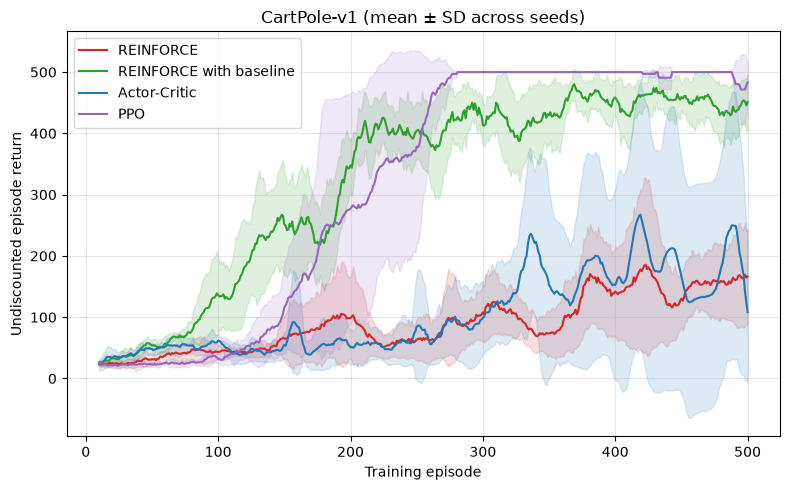

In [8]:
ALL["CartPole-v1"] = run_env_cached("CartPole-v1")
plot_env("CartPole-v1", ALL["CartPole-v1"])

### Acrobot-v1

Training Acrobot-v1 | REINFORCE | seed 0
Training Acrobot-v1 | REINFORCE | seed 1
Training Acrobot-v1 | REINFORCE | seed 2
Training Acrobot-v1 | REINFORCE | seed 3
Training Acrobot-v1 | REINFORCE | seed 4
Acrobot-v1 | REINFORCE: last 50 mean = -474.8 ± 47.2 (SD across seeds)
Training Acrobot-v1 | REINFORCE with baseline | seed 0
Training Acrobot-v1 | REINFORCE with baseline | seed 1
Training Acrobot-v1 | REINFORCE with baseline | seed 2
Training Acrobot-v1 | REINFORCE with baseline | seed 3
Training Acrobot-v1 | REINFORCE with baseline | seed 4
Acrobot-v1 | REINFORCE with baseline: last 50 mean = -87.7 ± 4.9 (SD across seeds)
Training Acrobot-v1 | Actor-Critic | seed 0
Training Acrobot-v1 | Actor-Critic | seed 1
Training Acrobot-v1 | Actor-Critic | seed 2
Training Acrobot-v1 | Actor-Critic | seed 3
Training Acrobot-v1 | Actor-Critic | seed 4
Acrobot-v1 | Actor-Critic: last 50 mean = -417.4 ± 165.1 (SD across seeds)
Training Acrobot-v1 | PPO | seed 0
Training Acrobot-v1 | PPO | seed 1
T

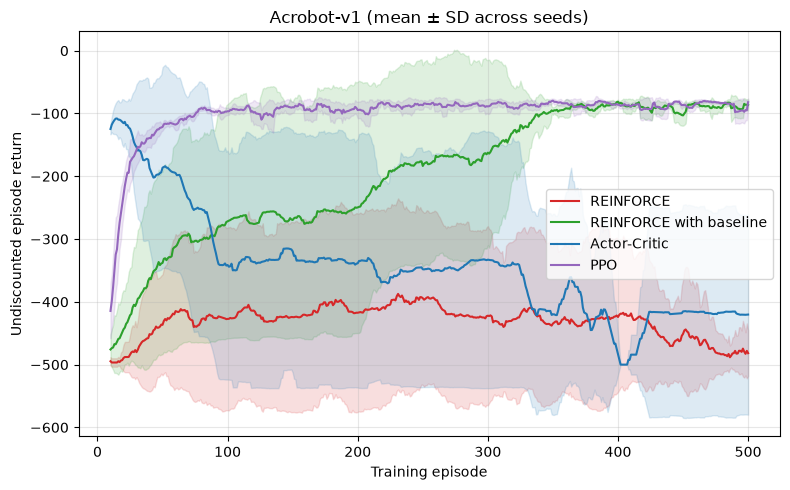

In [9]:
ALL["Acrobot-v1"] = run_env_cached("Acrobot-v1")
plot_env("Acrobot-v1", ALL["Acrobot-v1"])

### LunarLander-v3

Training LunarLander-v3 | REINFORCE | seed 0


C:\Users\16174\AppData\Local\Programs\Python\Python313\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


Training LunarLander-v3 | REINFORCE | seed 1
Training LunarLander-v3 | REINFORCE | seed 2
Training LunarLander-v3 | REINFORCE | seed 3
Training LunarLander-v3 | REINFORCE | seed 4
LunarLander-v3 | REINFORCE: last 50 mean = -57.6 ± 38.6 (SD across seeds)
Training LunarLander-v3 | REINFORCE with baseline | seed 0
Training LunarLander-v3 | REINFORCE with baseline | seed 1
Training LunarLander-v3 | REINFORCE with baseline | seed 2
Training LunarLander-v3 | REINFORCE with baseline | seed 3
Training LunarLander-v3 | REINFORCE with baseline | seed 4
LunarLander-v3 | REINFORCE with baseline: last 50 mean = -78.7 ± 23.9 (SD across seeds)
Training LunarLander-v3 | Actor-Critic | seed 0
Training LunarLander-v3 | Actor-Critic | seed 1
Training LunarLander-v3 | Actor-Critic | seed 2
Training LunarLander-v3 | Actor-Critic | seed 3
Training LunarLander-v3 | Actor-Critic | seed 4
LunarLander-v3 | Actor-Critic: last 50 mean = -74.3 ± 60.8 (SD across seeds)
Training LunarLander-v3 | PPO | seed 0
Trainin

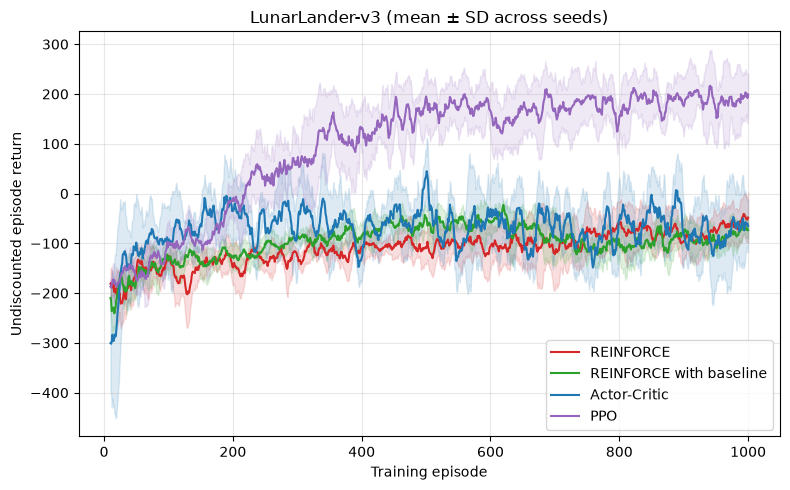

In [10]:
ALL["LunarLander-v3"] = run_env_cached("LunarLander-v3")
plot_env("LunarLander-v3", ALL["LunarLander-v3"])

### Pendulum-v1

Training Pendulum-v1 | REINFORCE | seed 0
Training Pendulum-v1 | REINFORCE | seed 1
Training Pendulum-v1 | REINFORCE | seed 2
Training Pendulum-v1 | REINFORCE | seed 3
Training Pendulum-v1 | REINFORCE | seed 4
Pendulum-v1 | REINFORCE: last 50 mean = -1488.8 ± 117.3 (SD across seeds)
Training Pendulum-v1 | REINFORCE with baseline | seed 0
Training Pendulum-v1 | REINFORCE with baseline | seed 1
Training Pendulum-v1 | REINFORCE with baseline | seed 2
Training Pendulum-v1 | REINFORCE with baseline | seed 3
Training Pendulum-v1 | REINFORCE with baseline | seed 4
Pendulum-v1 | REINFORCE with baseline: last 50 mean = -1333.4 ± 201.8 (SD across seeds)
Training Pendulum-v1 | Actor-Critic | seed 0
Training Pendulum-v1 | Actor-Critic | seed 1
Training Pendulum-v1 | Actor-Critic | seed 2
Training Pendulum-v1 | Actor-Critic | seed 3
Training Pendulum-v1 | Actor-Critic | seed 4
Pendulum-v1 | Actor-Critic: last 50 mean = -1399.5 ± 131.4 (SD across seeds)
Training Pendulum-v1 | PPO | seed 0
Training P

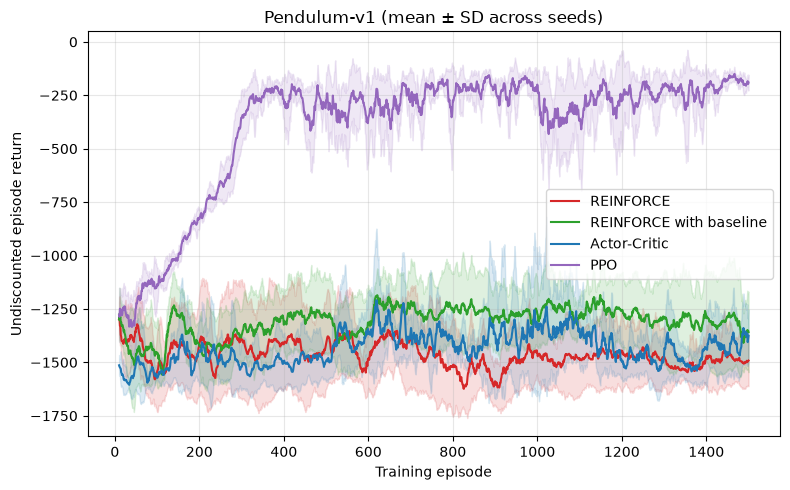

In [11]:
ALL["Pendulum-v1"] = run_env_cached("Pendulum-v1")
plot_env("Pendulum-v1", ALL["Pendulum-v1"])

### CliffWalking-v1

Training CliffWalking-v1 | REINFORCE | seed 0
Training CliffWalking-v1 | REINFORCE | seed 1
Training CliffWalking-v1 | REINFORCE | seed 2
Training CliffWalking-v1 | REINFORCE | seed 3
Training CliffWalking-v1 | REINFORCE | seed 4
CliffWalking-v1 | REINFORCE: last 50 mean = -246.7 ± 17.8 (SD across seeds)
Training CliffWalking-v1 | REINFORCE with baseline | seed 0
Training CliffWalking-v1 | REINFORCE with baseline | seed 1
Training CliffWalking-v1 | REINFORCE with baseline | seed 2
Training CliffWalking-v1 | REINFORCE with baseline | seed 3
Training CliffWalking-v1 | REINFORCE with baseline | seed 4
CliffWalking-v1 | REINFORCE with baseline: last 50 mean = -256.2 ± 11.1 (SD across seeds)
Training CliffWalking-v1 | Actor-Critic | seed 0
Training CliffWalking-v1 | Actor-Critic | seed 1
Training CliffWalking-v1 | Actor-Critic | seed 2
Training CliffWalking-v1 | Actor-Critic | seed 3
Training CliffWalking-v1 | Actor-Critic | seed 4
CliffWalking-v1 | Actor-Critic: last 50 mean = -90.3 ± 89.6

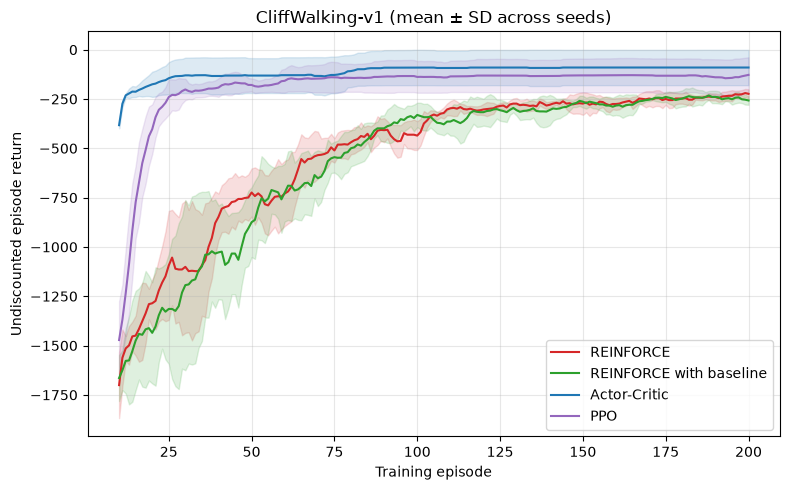

In [12]:
ALL["CliffWalking-v1"] = run_env_cached("CliffWalking-v1")
plot_env("CliffWalking-v1", ALL["CliffWalking-v1"])

## 4. Summary and discussion

In [13]:
summary_rows = []
for env_name, results in ALL.items():
    for algo, arr in results.items():
        last50 = arr[:, -50:].mean(axis=1)
        summary_rows.append((env_name, algo, len(last50), last50.mean(), last50.std()))
print(f"{'Environment':20s} {'Algorithm':25s} {'Seeds':>5s} {'Mean':>10s} {'SD':>10s}")
for env_name, algo, n, mean, sd in summary_rows:
    print(f"{env_name:20s} {algo:25s} {n:5d} {mean:10.1f} {sd:10.1f}")
with (RESULTS_DIR / "summary.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["environment", "algorithm", "seeds", "last_50_mean", "last_50_sd_across_seeds"])
    writer.writerows(summary_rows)
print("Saved:", RESULTS_DIR / "summary.csv")

Environment          Algorithm                 Seeds       Mean         SD
CartPole-v1          REINFORCE                     5      160.1       56.1
CartPole-v1          REINFORCE with baseline       5      447.3       31.2
CartPole-v1          Actor-Critic                  5      160.3      153.3
CartPole-v1          PPO                           5      494.3       11.4
Acrobot-v1           REINFORCE                     5     -474.8       47.2
Acrobot-v1           REINFORCE with baseline       5      -87.7        4.9
Acrobot-v1           Actor-Critic                  5     -417.4      165.1
Acrobot-v1           PPO                           5      -85.7        3.6
LunarLander-v3       REINFORCE                     5      -57.6       38.6
LunarLander-v3       REINFORCE with baseline       5      -78.7       23.9
LunarLander-v3       Actor-Critic                  5      -74.3       60.8
LunarLander-v3       PPO                           5      188.2       54.3
Pendulum-v1          REIN

These results compare complete algorithm implementations under the same episode budgets, not the same number of environment steps or gradient updates. PPO also combines several techniques, so the results cannot attribute its performance to clipping alone. Finally, the reported means are based on five seeds and training returns; independent evaluation episodes and additional seeds would provide stronger evidence about the final policies.